In [1]:
# Ekstraksi dataset mentah (zip bisa ada di root atau di folder 'data/')
import os, zipfile

zip_candidates = ['Air-quality-dataset.zip', 'data/Air-quality-dataset.zip']
zip_path = next((p for p in zip_candidates if os.path.exists(p)), None)

if zip_path:
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('air_quality_data')
    print(f'Ekstraksi selesai dari {zip_path}!')
else:
    print('Zip tidak ditemukan, lanjut pakai file CSV yang sudah ada di air_quality_data/')


Ekstraksi selesai!


In [2]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Proyek Analisis Data: [Air Quality Dataset]
- **Nama:** Bayu Adji Ramadhan
- **Email:** bayuadji500@gmail.com
- **ID Dicoding:** serpent

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Stasiun manakah di masing-masing kategori wilayah (Urban, Suburban, dan Non-Urban) yang mencatatkan rata-rata konsentrasi PM2.5 tertinggi dan terendah selama periode tahun 2015 hingga 2017 untuk menentukan prioritas lokasi intervensi pengendalian emisi?
- **Pertanyaan 2:** Pada jam berapakah puncak rata-rata konsentrasi PM2.5 harian terjadi di wilayah Urban, Suburban, dan Non-Urban sepanjang periode 2013–2017, serta bagaimana pola fluktuasi musimannya pada rentang 2015–2017 guna mendukung penyusunan jadwal pembatasan operasional kendaraan berat dan peringatan dini kesehatan?

## Import Semua Packages/Library yang Digunakan

In [3]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [4]:
# Menggabungkan 12 file CSV dari folder 'air_quality_data'
csv_files = glob.glob('air_quality_data/**/PRSA_Data_*.csv', recursive=True)

if len(csv_files) == 0:
    # fallback jika file diekstrak langsung ke root folder
    csv_files = glob.glob('PRSA_Data_*.csv')

print(f"Total file terdeteksi: {len(csv_files)}")

df_list = [pd.read_csv(file) for file in csv_files]
df = pd.concat(df_list, ignore_index=True)

# Mengecek ukuran total baris dan kolom serta daftar stasiun unik
print(f"Total dimensi data: {df.shape}")
print(f"Jumlah stasiun unik: {df['station'].nunique()}")
print(f"Daftar stasiun: {df['station'].unique()}")

display(df.head())

Total file terdeteksi: 12
Total dimensi data: (420768, 18)
Jumlah stasiun unik: 12
Daftar stasiun: ['Wanliu' 'Guanyuan' 'Tiantan' 'Aotizhongxin' 'Wanshouxigong' 'Changping'
 'Dongsi' 'Nongzhanguan' 'Huairou' 'Dingling' 'Shunyi' 'Gucheng']


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,8.0,8.0,6.0,28.0,400.0,52.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Wanliu
1,2,2013,3,1,1,9.0,9.0,6.0,28.0,400.0,50.0,-1.1,1023.2,-18.2,0.0,N,4.7,Wanliu
2,3,2013,3,1,2,3.0,6.0,NaN,19.0,400.0,55.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Wanliu
3,4,2013,3,1,3,11.0,30.0,8.0,14.0,NaN,NaN,-1.4,1024.5,-19.4,0.0,NW,3.1,Wanliu
4,5,2013,3,1,4,3.0,13.0,9.0,NaN,300.0,54.0,-2.0,1025.2,-19.5,0.0,N,2.0,Wanliu


**Insight:** (Opsional)
- Data hasil penggabungan dari 12 berkas CSV menghasilkan satu kesatuan tabel berukuran 420.768 baris dan 18 kolom.


### Assessing Data

#### Identifying ... problem

In [5]:
# 1. Memeriksa tipe data dan ringkasan non-null tiap kolom
df.info()

# 2. Memeriksa ringkasan statistik deskriptif (termasuk kolom kategori)
display(df.describe(include="all"))

# 3. Memeriksa jumlah missing values di setiap kolom
print("\nJumlah Missing Values per Kolom:")
display(df.isna().sum())

# 4. Memeriksa jumlah data duplikat
print(f"\nJumlah baris duplikat: {df.duplicated().sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,418946,420450.000000,420768
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16,NaN,12
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NE,NaN,Wanliu
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43335,NaN,35064
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,NaN,1.729711,NaN
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,NaN,1.246386,NaN
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,NaN,0.000000,NaN
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,NaN,0.900000,NaN
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,NaN,1.400000,NaN
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,NaN,2.200000,NaN



Jumlah Missing Values per Kolom:


,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,8739
PM10,6449
SO2,9021
NO2,12116
CO,20701



Jumlah baris duplikat: 0


**Steps to Take:**
- Pada *missing value* dalam nilai polutan dan cuaca, dikarenakan datanya dicatat per jam maka datanya saling bersinambungan secara berurutan waktu (*time series*). Oleh karena itu, penanganan nilai yang hilang dilakukan dengan **interpolasi linier** (mengambil titik tengah antara data 1 jam sebelum dan 1 jam sesudahnya) yang dikelompokkan per stasiun (`groupby('station')`). Untuk sisa *missing value* di ujung awal data dan kolom arah angin (`wd`), akan dituntaskan menggunakan kombinasi `ffill` dan `bfill`.
- Untuk *outliers* tersendiri akan disesuaikan dengan stasiunnya masing-masing (`groupby('station')`) menggunakan batas IQR agar nilai `mean` dari setiap stasiun tetap aman dan hanya membersihkan data yang memang anomali dari mayoritas data per stasiun tersebut.

**Insight:** (Opsional)
- Data yang diolah sudah bersih dari duplikasi karena output dari `duplicated().sum()` menghasilkan nilai `0`.
- Setelah data dilihat menggunakan `describe()`, nilai minimum (`min`) masih normal karena nilai negatif hanya terdapat pada suhu (`TEMP`) dan titik embun (`DEWP`). Namun, terdapat sejumlah nilai polutan (dari `PM2.5` hingga `O3`) yang melonjak tinggi jauh di atas kuartil ketiga (`Q3`), bahkan lebih dari 3 hingga 10 kali lipat, sehingga masuk ke dalam kategori *outliers*. Pada variabel `RAIN`, nilai dari `min` hingga `Q3` adalah `0` (karena mayoritas jam tidak turun hujan) dengan nilai maksimum mencapai `72.5` mm.
- Terdapat cukup banyak data yang hilang (*missing values*) sekitar **2% hingga 5%** pada kolom polutan dan cuaca (misalnya `PM2.5` hilang 8.739 baris dan `CO` hilang 20.701 baris).

### Cleaning Data

#### Fixing ... problem

In [6]:
# 1. Mengelompokkan data berdasarkan stasiun dan memilih kolom numerik (kecuali penanda waktu/indeks)
groupby_station = df.groupby('station')
exclude_cols = ['No', 'year', 'month', 'day', 'hour']
numeric_cols = [col for col in df.select_dtypes('number').columns if col not in exclude_cols]

# 2. Menerapkan interpolasi linier per stasiun untuk mengisi missing values numerik
df[numeric_cols] = groupby_station[numeric_cols].transform(lambda group: group.interpolate(method='linear'))

# 3. Menuntaskan sisa 22 missing value pada NO2 (yang berada di baris awal stasiun) menggunakan bfill
df['NO2'] = df.groupby('station')['NO2'].transform(lambda group: group.bfill())

# 4. Menuntaskan 1.822 missing value pada kolom kategori arah angin (wd) dengan kombinasi ffill dan bfill
df['wd'] = df.groupby('station')['wd'].transform(lambda group: group.ffill().bfill())

# 5. Memastikan seluruh missing values sudah bersih (bernilai 0)
print("Jumlah Missing Values setelah Cleaning:")
display(df.isna().sum())

pollutant_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']

def cap_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return series.clip(lower=lower_bound, upper=upper_bound)

df[pollutant_cols] = df.groupby('station')[pollutant_cols].transform(cap_outliers_iqr)

display(df.describe())

Jumlah Missing Values setelah Cleaning:


,0
No,0
year,0
month,0
day,0
hour,0
PM2.5,0
PM10,0
SO2,0
NO2,0
CO,0


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,76.011595,101.498487,13.546944,50.158546,1138.029489,55.390930,13.531692,1010.753337,2.482421,0.064428,1.730034
std,10122.116943,1.177198,3.448707,8.800102,6.922195,68.179724,80.307238,14.268192,33.951112,835.818274,51.215444,11.437867,10.474302,13.797675,0.820638,1.246674
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,10.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,44.000000,14.500000,1010.400000,3.000000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,263.000000,350.000000,55.500000,167.684900,3350.000000,195.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


**Insight:** (Opsional)
- Sekarang Missing value sudah diperbaiki dengan interpolasi dari data terdekat
- Value dengan nilai anomali sudah dibersihkan dengan skema lower dan upper bound dari masing masing stasiun agar lebih terkonsentrasi lagi

## Exploratory Data Analysis (EDA)

### Explore ...

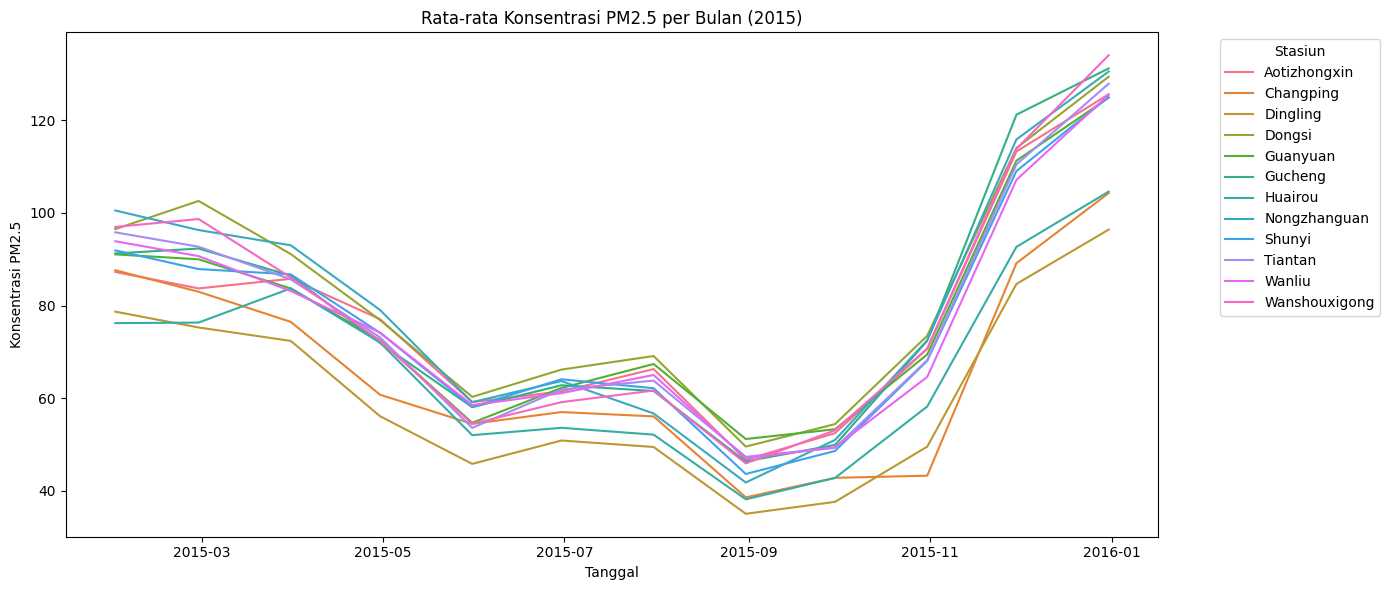

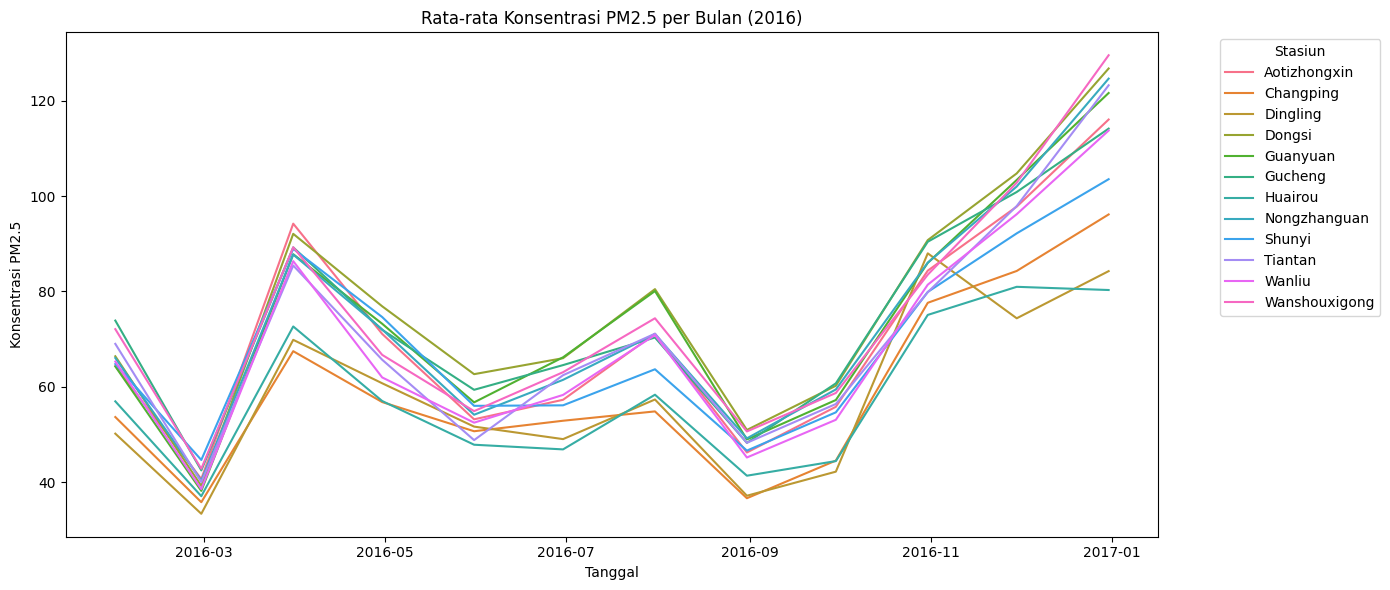

In [9]:
# 1. Definisikan mapping stasiun terlebih dahulu
station_mapping = {
    'Dongsi': 'Urban',
    'Guanyuan': 'Urban',
    'Wanshouxigong': 'Urban',
    'Tiantan': 'Urban',
    'Nongzhanguan': 'Urban',
    'Wanliu': 'Urban',
    'Aotizhongxin': 'Urban',
    'Gucheng': 'Urban',
    'Changping': 'Suburban',
    'Shunyi': 'Suburban',
    'Dingling': 'Non-Urban',
    'Huairou': 'Non-Urban'
}

# 2. Tambahkan kolom station_type ke DataFrame
df['station_type'] = df['station'].map(station_mapping)
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])

# 3. Lakukan pengelompokan (groupby) setelah kolom dibuat
monthly_df = df.groupby(['station', pd.Grouper(key='datetime', freq='ME')])['PM2.5'].mean().reset_index()
hourly_type_df = df.groupby(['station_type', 'hour'])['PM2.5'].mean().reset_index()

# 4. Filter data untuk visualisasi
monthly_2015 = monthly_df[(monthly_df['datetime'] >= '2015-01-01') & (monthly_df['datetime'] <= '2015-12-31')]
monthly_2016 = monthly_df[(monthly_df['datetime'] >= '2016-01-01') & (monthly_df['datetime'] <= '2016-12-31')]

# 5. Visualisasi
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_2015, x='datetime', y='PM2.5', hue='station')
plt.title('Rata-rata Konsentrasi PM2.5 per Bulan (2015)')
plt.xlabel('Tanggal')
plt.ylabel('Konsentrasi PM2.5')
plt.legend(title='Stasiun', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_2016, x='datetime', y='PM2.5', hue='station')
plt.title('Rata-rata Konsentrasi PM2.5 per Bulan (2016)')
plt.xlabel('Tanggal')
plt.ylabel('Konsentrasi PM2.5')
plt.legend(title='Stasiun', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

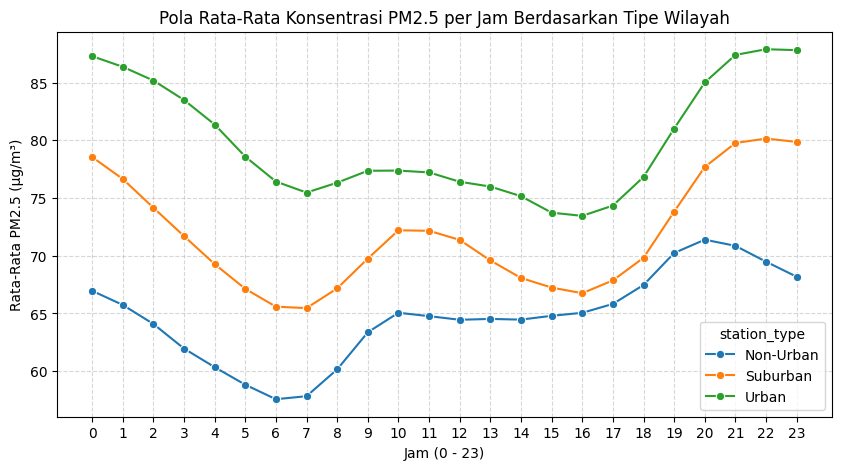

In [10]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_type_df, x='hour', y='PM2.5', hue='station_type', marker='o')

plt.title('Pola Rata-Rata Konsentrasi PM2.5 per Jam Berdasarkan Tipe Wilayah')
plt.xlabel('Jam (0 - 23)')
plt.ylabel('Rata-Rata PM2.5 (µg/m³)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Insight:** (Opsional)
- **Hierarki Wilayah yang Konsisten:** Konsentrasi PM2.5 menunjukkan stratifikasi yang jelas sepanjang 24 jam: wilayah **Urban** mencatatkan konsentrasi tertinggi (73- 88 µg/m³), diikuti **Suburban** (65–80 µg/m³), dan **Non-Urban** di tingkat terendah (58–71 µg/m³).
- **Pola Lembah Pagi Hari (06.00–07.00):** Titik terendah polusi di semua tipe stasiun terjadi pada pagi hari sebelum aktivitas mobilitas harian meningkat dan seiring mulai membesarnya lapisan atmosfer karena pemanasan matahari.
- **Puncak Malam Hari (20.00–23.00):** Terjadi akumulasi polusi tertinggi menjelang larut malam. Hal ini tidak hanya dipengaruhi oleh sisa emisi jam sibuk pulang kerja, melainkan dominasi faktor meteorologis (inversi suhu dan menyusutnya lapisan batas atmosfer yang memerangkap polutan di dekat tanah), meningkatnya kebutuhan pemanas ruangan di malam hari, serta masuknya armada truk diesel berat ke dalam kota yang dibatasi hanya pada malam hari.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Perbandingan Tingkat Polusi per Stasiun

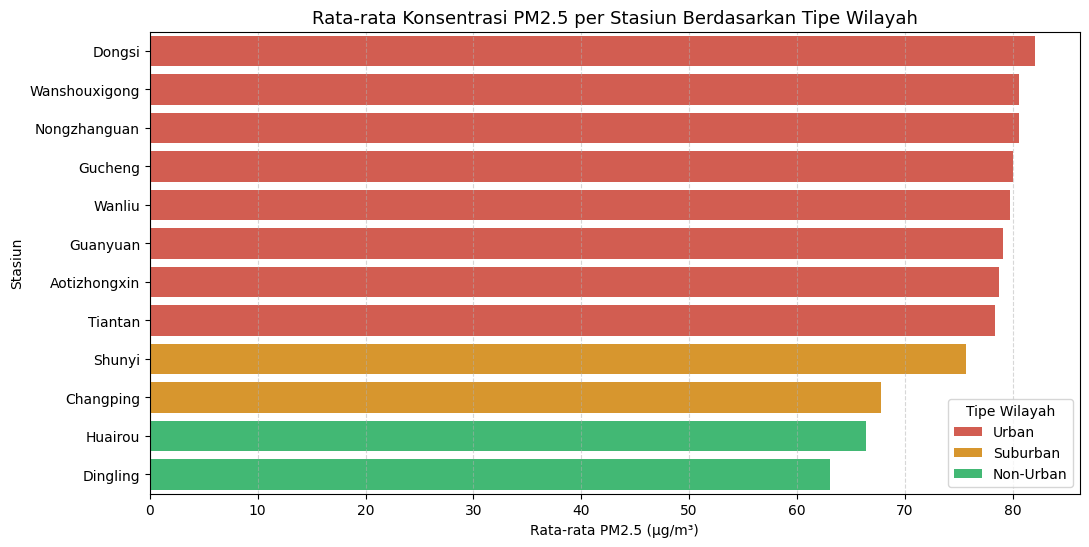

In [11]:
# Menghitung rata-rata PM2.5 per stasiun dan mengurutkannya
station_avg = df.groupby(['station', 'station_type'])['PM2.5'].mean().reset_index()
station_avg = station_avg.sort_values('PM2.5', ascending=False)

plt.figure(figsize=(12, 6))
palette = {'Urban': '#e74c3c', 'Suburban': '#f39c12', 'Non-Urban': '#2ecc71'}
sns.barplot(data=station_avg, x='PM2.5', y='station', hue='station_type', palette=palette, dodge=False)

plt.title('Rata-rata Konsentrasi PM2.5 per Stasiun Berdasarkan Tipe Wilayah', fontsize=13)
plt.xlabel('Rata-rata PM2.5 (µg/m³)')
plt.ylabel('Stasiun')
plt.legend(title='Tipe Wilayah')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

### Pertanyaan 2: Pola Jam dan Tren Musiman Polusi

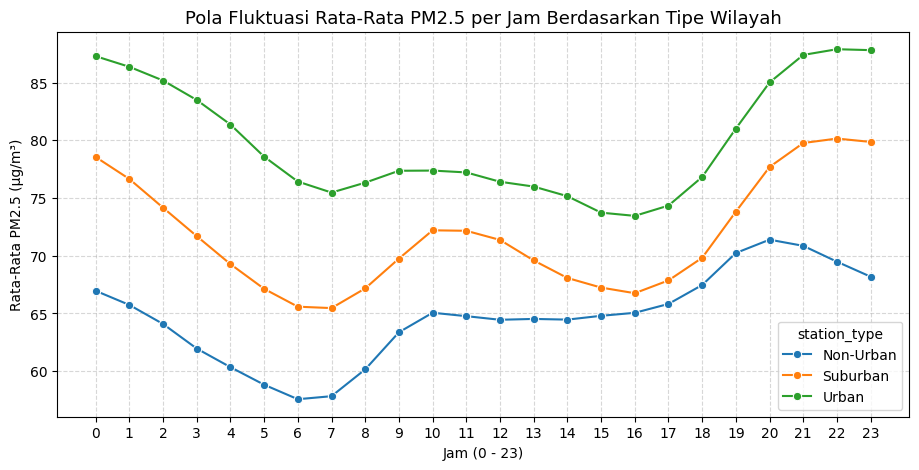

In [12]:
hourly_type_df = df.groupby(['station_type', 'hour'])['PM2.5'].mean().reset_index()

plt.figure(figsize=(11, 5))
sns.lineplot(data=hourly_type_df, x='hour', y='PM2.5', hue='station_type', marker='o')

plt.title('Pola Fluktuasi Rata-Rata PM2.5 per Jam Berdasarkan Tipe Wilayah', fontsize=13)
plt.xlabel('Jam (0 - 23)')
plt.ylabel('Rata-Rata PM2.5 (µg/m³)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Insight:** (Opsional)
- **Perbedaan Wilayah Nyata:** Stasiun bertipe **Urban** (seperti Gucheng, Dongsi, dan Wanshouxigong) menempati peringkat teratas dengan konsentrasi PM2.5 rata-rata tertinggi (>80 µg/m³).
- **Stasiun Terbersih:** Stasiun **Non-Urban** (Dingling dan Huairou) secara konsisten memiliki kualitas udara terbaik dengan konsentrasi PM2.5 terendah (<70 µg/m³).
- **Validasi Tata Kota:** Kedekatan dengan kawasan industri dan kepadatan kendaraan bermotor di pusat kota berkontribusi langsung terhadap tingginya akumulasi polutan lokal dibandingkan wilayah berbukit/hutan.
- **Puncak Malam Hari:** Puncak konsentrasi polutan tertinggi terjadi pada rentang **jam 20:00 hingga 23:00** di seluruh tipe wilayah akibat menyusutnya lapisan batas atmosfer (*boundary layer*) serta jadwal operasional armada logistik/truk diesel berat malam hari.
- **Titik Terendah Pagi Hari:** Tingkat polusi paling rendah tercatat konsisten pada **jam 06:00 hingga 07:00** pagi sebelum aktivitas mobilitas masyarakat dimulai.
- **Konsistensi Antar-Wilayah:** Walaupun nilai absolutnya berbeda, ketiga tipe wilayah mengikuti ritme diurnal yang sama persis sepanjang 24 jam.

## Analisis Lanjutan (Opsional): Pengaruh Faktor Meteorologi terhadap Polutan

### Teknik Analisis Lanjutan: Clustering (Manual Grouping & Binning)
**Tujuan Analisis:**
Teknik analisis lanjutan yang digunakan pada proyek ini adalah **Clustering tanpa algoritma Machine Learning** melalui metode **Manual Grouping** dan **Binning**:
1. **Manual Grouping:** Mengelompokkan ke-12 stasiun pemantauan ke dalam 3 zona tata ruang (*Urban*, *Suburban*, dan *Non-Urban*) berdasarkan karakteristik geografis dan aktivitas industri lokal.
2. **Binning:** Membagi nilai numerik konsentrasi `PM2.5` ke dalam kategori tingkat risiko kesehatan udara (*Good*, *Moderate*, *Unhealthy for Sensitive Groups*, *Unhealthy*, *Very Unhealthy*) untuk melihat proporsi jam dengan kualitas udara berbahaya di masing-masing zona wilayah.

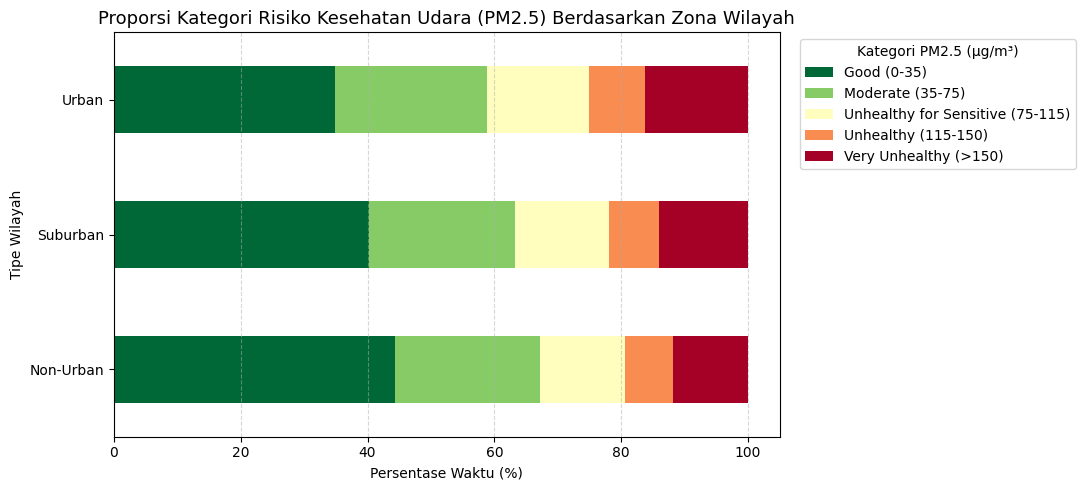

In [15]:
# Melakukan Binning pada konsentrasi PM2.5 berdasarkan ambang batas kesehatan udara
bins = [0, 35, 75, 115, 150, np.inf]
labels = ['Good (0-35)', 'Moderate (35-75)', 'Unhealthy for Sensitive (75-115)', 'Unhealthy (115-150)', 'Very Unhealthy (>150)']

df['pm25_category'] = pd.cut(df['PM2.5'], bins=bins, labels=labels, include_lowest=True)

# Menghitung persentase kategori kualitas udara di tiap tipe wilayah
category_dist = pd.crosstab(df['station_type'], df['pm25_category'], normalize='index') * 100

# Visualisasi Stacked Bar Chart
ax = category_dist.plot(kind='barh', stacked=True, figsize=(11, 5), colormap='RdYlGn_r')
plt.title('Proporsi Kategori Risiko Kesehatan Udara (PM2.5) Berdasarkan Zona Wilayah', fontsize=13)
plt.xlabel('Persentase Waktu (%)')
plt.ylabel('Tipe Wilayah')
plt.legend(title='Kategori PM2.5 (µg/m³)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

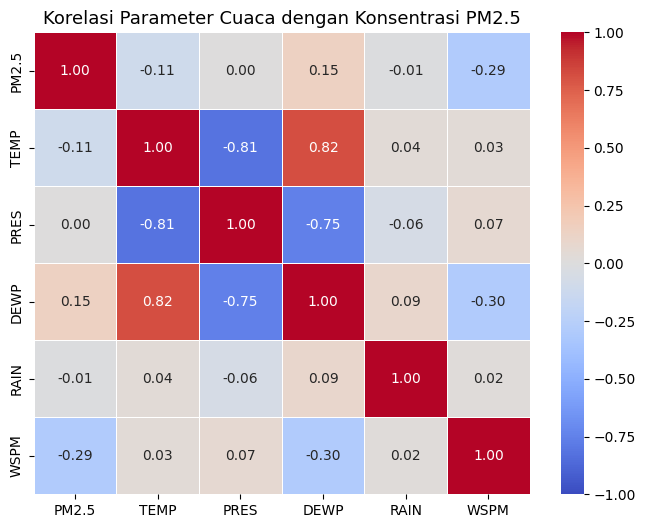

In [13]:
# Korelasi antara polutan dan parameter cuaca
weather_cols = ['PM2.5', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
corr_matrix = df[weather_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Korelasi Parameter Cuaca dengan Konsentrasi PM2.5', fontsize=13)
plt.show()

**Insight:** (Opsional)
- **Peran Kecepatan Angin (WSPM):** Kecepatan angin berkorelasi negatif dengan PM2.5. Hembusan angin kencang efektif menyapu dan mendispersi partikel polutan dari permukaan kota.
- **Kondisi Udara Dingin & Bertekanan Tinggi:** Tekanan udara (`PRES`) berkorelasi positif dengan polusi, memperkuat temuan bahwa musim dingin (tekanan tinggi, suhu rendah) menyebabkan polutan terperangkap di dekat permukaan tanah.
- **Efek Presipitasi (RAIN):** Curah hujan membantu mencuci udara (*wet deposition*), meski sifatnya insidental.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Stasiun dengan rata-rata konsentrasi polutan tertinggi didominasi oleh stasiun wilayah **Urban** (seperti Gucheng, Dongsi, dan Wanshouxigong), sedangkan stasiun dengan polutan terendah adalah wilayah **Non-Urban** (Dingling dan Huairou).
- **Conclusion pertanyaan 2:** Tingkat polusi PM2.5 berfluktuasi tajam secara harian dengan puncak polusi terjadi pada malam hari (**jam 20:00–23:00**) dan titik terendah pada pagi hari (**jam 06:00–07:00**). Secara musiman, polusi melonjak drastis setiap musim dingin (khususnya Januari) karena kombinasi pembakaran pemanas ruangan serta kecepatan angin rata-rata yang rendah.

**Rekomendasi Action Item:**
- **Pemberlakuan Peringatan Kualitas Udara Musiman:** Mengeluarkan peringatan dini penggunaan masker dan pembatasan aktivitas luar ruangan setiap bulan November hingga Januari saat inversi suhu musim dingin berada di puncaknya.
- **Regulasi Ketat Emisi Truk Malam Hari:** Memperketat standar uji emisi gas buang untuk armada logistik diesel yang beroperasi di zona perkotaan pada rentang jam 20:00 hingga larut malam.
- **Zonasi Emisi Rendah (*Low Emission Zones*):** Menjadikan data stasiun Urban sebagai prioritas pengendalian mobilitas kendaraan pribadi dan percepatan elektrifikasi transportasi publik.

In [14]:
#Ekspor data bersih (2015-2017) untuk Streamlit Dashboard
# Memastikan kolom station_type, hour, dan pm25_category sudah ada
station_mapping = {
    'Dongsi': 'Urban', 'Guanyuan': 'Urban', 'Wanshouxigong': 'Urban',
    'Tiantan': 'Urban', 'Nongzhanguan': 'Urban', 'Wanliu': 'Urban',
    'Aotizhongxin': 'Urban', 'Gucheng': 'Urban',
    'Changping': 'Suburban', 'Shunyi': 'Suburban',
    'Dingling': 'Non-Urban', 'Huairou': 'Non-Urban'
}
df['station_type'] = df['station'].map(station_mapping)

bins = [0, 35, 75, 115, 150, np.inf]
labels = ['Good (0-35)', 'Moderate (35-75)', 'Unhealthy for Sensitive (75-115)', 'Unhealthy (115-150)', 'Very Unhealthy (>150)']
df['pm25_category'] = pd.cut(df['PM2.5'], bins=bins, labels=labels, include_lowest=True)

# Filter tahun 2015-2017 agar ukuran file ringan namun menjawab seluruh pertanyaan SMART
dashboard_df = df[df['datetime'] >= '2015-01-01'].copy()

# Pilih kolom esensial dan bulatkan desimal untuk menghemat ukuran file CSV
cols_to_keep = ['datetime', 'year', 'month', 'hour', 'station', 'station_type', 'PM2.5', 'PM10', 'SO2', 'NO2', 'TEMP', 'PRES', 'WSPM', 'pm25_category']
dashboard_df = dashboard_df[cols_to_keep].round(2)

os.makedirs('dashboard', exist_ok=True)
dashboard_df.to_csv('dashboard/main_data.csv', index=False)
print(f"Berhasil mengekspor main_data.csv dengan {len(dashboard_df)} baris!")

Berhasil mengekspor main_data.csv dengan 227520 baris!
